# Лабораторна робота №5 — Основи штучного інтелекту
## Завдання 1. Класифікація бінарних зображень 4×4 за допомогою MLP

**Мета:** дослідити класифікацію рукописних цифр **0 і 1** за 16 бінарними ознаками; навчити багатошаровий перцептрон (`MLPClassifier`), оптимізувати його гіперпараметри методом перехресної перевірки та оцінити якість на відкладеній тестовій вибірці.

Набір із 20 зображень відтворено за прикладом В. Б. Копея `my_number_classify.py` (10 зображень класу 0, 10 класу 1). Оригінальний приклад використовує KNN; у цій роботі додано MLP та пошук оптимальних параметрів.

**Джерело даних:** https://github.com/vkopey/sklearn_examples/blob/main/my_number_classify.py

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 9
OUT = Path("results")
OUT.mkdir(exist_ok=True)
np.random.seed(SEED)
print("Environment ready; seed =", SEED)

Environment ready; seed = 9


### 1. Початкові дані

Піксель `x` кодується одиницею (1), крапка — нулем (0). Кожне зображення займає чотири рядки по чотири пікселі, тобто один об'єкт описано 16 ознаками.

Samples: 20 | features: 16 | class 0: 10 | class 1: 10


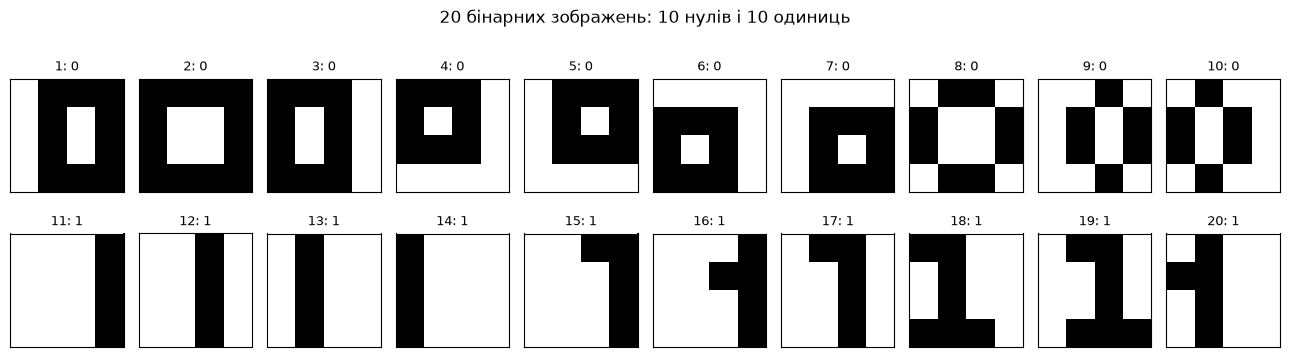

In [2]:
zero = """
.xxx
.x.x
.x.x
.xxx

xxxx
x..x
x..x
xxxx

xxx.
x.x.
x.x.
xxx.

xxx.
x.x.
xxx.
....

.xxx
.x.x
.xxx
....

....
xxx.
x.x.
xxx.

....
.xxx
.x.x
.xxx

.xx.
x..x
x..x
.xx.

..x.
.x.x
.x.x
..x.

.x..
x.x.
x.x.
.x..
"""

one = """
...x
...x
...x
...x

..x.
..x.
..x.
..x.

.x..
.x..
.x..
.x..

x...
x...
x...
x...

..xx
...x
...x
...x

...x
..xx
...x
...x

.xx.
..x.
..x.
..x.

xx..
.x..
.x..
xxx.

.xx.
..x.
..x.
.xxx

.x..
xx..
.x..
.x..
"""

def decode_digits(text):
    blocks = [b.strip().splitlines() for b in text.strip().split("\n\n")]
    assert all(len(b) == 4 and all(len(line) == 4 for line in b) for b in blocks)
    return np.array([[int(p == 'x') for line in b for p in line] for b in blocks], dtype=np.float64)

X = np.vstack([decode_digits(zero), decode_digits(one)])
y = np.array([0]*10 + [1]*10)
assert X.shape == (20, 16) and y.shape == (20,)
assert np.all(np.isin(X, [0,1]))
print(f"Samples: {len(y)} | features: {X.shape[1]} | class 0: {(y==0).sum()} | class 1: {(y==1).sum()}")

fig, axes = plt.subplots(2, 10, figsize=(13, 3.9))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(4,4), cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(f"{i+1}: {y[i]}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('20 бінарних зображень: 10 нулів і 10 одиниць')
plt.tight_layout(); fig.savefig(OUT/'01_digits.png', dpi=170, bbox_inches='tight'); plt.show()

### 2. Розбиття на навчальну та тестову частини

Виділяємо **30% даних** для фінальної перевірки; тестова частина **не бере участі** у підборі гіперпараметрів. Через дуже малий набір (лише 20 зображень) одна оцінка на шести тестових зразках може бути нестійкою.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
print("Навчальна вибірка:", X_train.shape, "Тестова:", X_test.shape)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_knn = knn.predict(X_test)
print("Базовий KNN (k=3), Accuracy test:", f"{accuracy_score(y_test, y_knn):.4f}")

Навчальна вибірка: (14, 16) Тестова: (6, 16)
Базовий KNN (k=3), Accuracy test: 0.5000


### 3. Оптимізація багатошарового перцептрона (MLP)

Використовуємо `GridSearchCV` з **триблоковою стратифікованою перехресною перевіркою** лише на навчальних даних. Підбираємо конфігурацію прихованих шарів, активацію та коефіцієнт L2-регуляризації `alpha`. Встановлено `random_state=9` для відтворюваності.

Оптимальні параметри: {'mlpclassifier__activation': 'relu', 'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (4,)}
Середня CV accuracy: 0.7667
architecture activation  alpha  CV_accuracy   CV_std  train_accuracy
        (4,)       relu 0.0001     0.766667 0.205480             1.0
      (8, 4)       relu 0.0001     0.700000 0.141421             1.0
     (12, 6)       relu 1.0000     0.700000 0.216025             1.0
        (4,)       tanh 0.0001     0.700000 0.216025             1.0
        (8,)       tanh 0.0001     0.700000 0.216025             1.0
     (12, 6)       tanh 0.0001     0.700000 0.216025             1.0
        (8,)       relu 0.0001     0.633333 0.124722             1.0
        (4,)       relu 0.0100     0.633333 0.124722             1.0
        (8,)       relu 0.0100     0.633333 0.124722             1.0
      (8, 4)       relu 0.0100     0.633333 0.124722             1.0


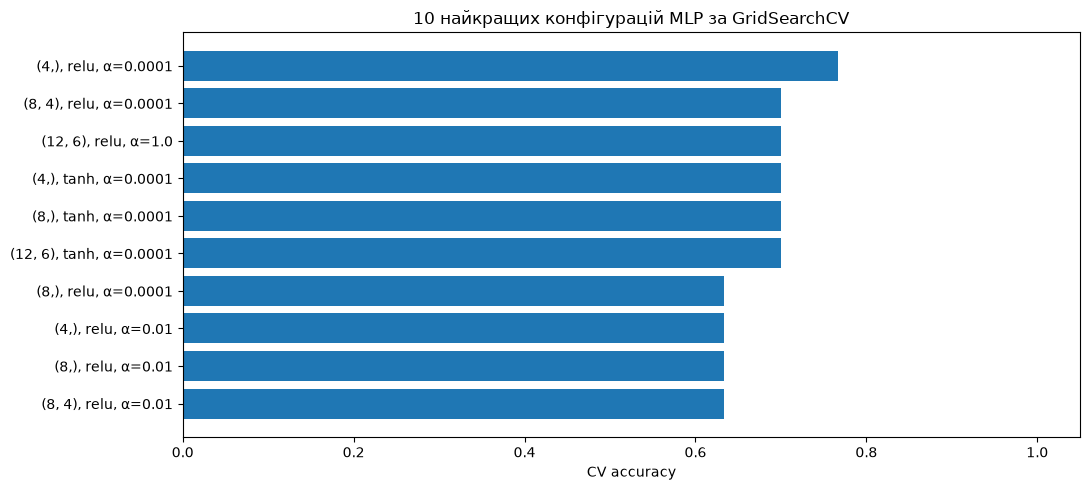

In [4]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
pipe = make_pipeline(
    StandardScaler(),
    MLPClassifier(solver='lbfgs', max_iter=1000, random_state=SEED)
)
param_grid = {
    'mlpclassifier__hidden_layer_sizes': [(4,), (8,), (8,4), (12,6)],
    'mlpclassifier__activation': ['relu','tanh'],
    'mlpclassifier__alpha': [0.0001, 0.01, 1.0],
}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    search = GridSearchCV(pipe, param_grid, scoring='accuracy', cv=cv,
                          return_train_score=True, refit=True, n_jobs=1)
    search.fit(X_train, y_train)

cv_results = pd.DataFrame(search.cv_results_)
cv_results['architecture'] = cv_results['param_mlpclassifier__hidden_layer_sizes'].astype(str)
cv_results['activation'] = cv_results['param_mlpclassifier__activation'].astype(str)
cv_results['alpha'] = cv_results['param_mlpclassifier__alpha'].astype(float)
summary = (cv_results[['architecture','activation','alpha','mean_test_score','std_test_score','mean_train_score']]
           .rename(columns={'mean_test_score':'CV_accuracy', 'std_test_score':'CV_std', 'mean_train_score':'train_accuracy'})
           .sort_values(['CV_accuracy','CV_std'],ascending=[False,True]))
summary.to_csv(OUT/'mlp_grid_search.csv', index=False, encoding='utf-8-sig')
print('Оптимальні параметри:', search.best_params_)
print(f'Середня CV accuracy: {search.best_score_:.4f}')
print(summary.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(11,5))
top = summary.head(10).copy()
labels = [f"{a}, {act}, α={alpha}" for a,act,alpha in zip(top.architecture,top.activation,top.alpha)]
ax.barh(np.arange(len(top)),top.CV_accuracy)
ax.set_yticks(np.arange(len(top)),labels)
ax.invert_yaxis(); ax.set_xlim(0,1.05)
ax.set_xlabel('CV accuracy'); ax.set_title('10 найкращих конфігурацій MLP за GridSearchCV')
plt.tight_layout(); fig.savefig(OUT/'02_mlp_cv_search.png',dpi=170,bbox_inches='tight');plt.show()

### 4. Перевірка на відкладеній тестовій вибірці

Обрану модель оцінюємо на шести відкладених зображеннях. Крім `Accuracy` та `F1`, будуємо матрицю помилок і відображаємо передбачення для кожного тестового зображення.

MLP test accuracy: 0.8333
MLP test F1: 0.8571
KNN test accuracy: 0.5000
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.75      1.00      0.86         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6



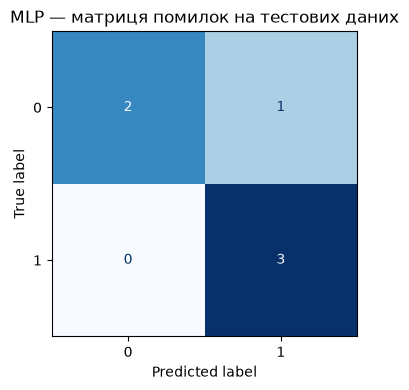

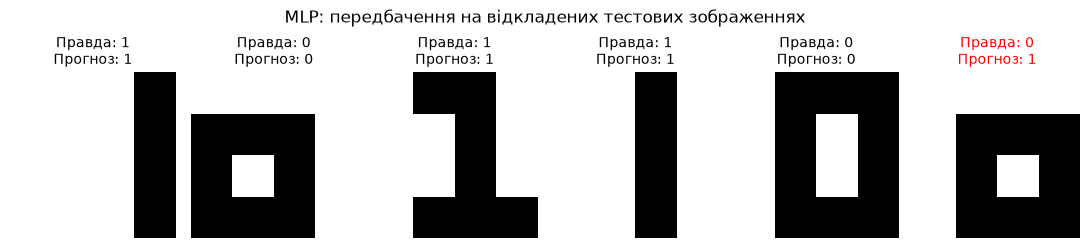

             model  test_accuracy  test_f1
         KNN (k=3)       0.500000 0.400000
MLP (GridSearchCV)       0.833333 0.857143


In [5]:
mlp = search.best_estimator_
y_pred = mlp.predict(X_test)
acc = accuracy_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred,zero_division=0)
print('MLP test accuracy:',f'{acc:.4f}')
print('MLP test F1:',f'{f1:.4f}')
print('KNN test accuracy:',f'{accuracy_score(y_test, y_knn):.4f}')
print('Classification report:')
print(classification_report(y_test,y_pred,zero_division=0))
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=[0,1],ax=ax,cmap='Blues',colorbar=False)
ax.set_title('MLP — матриця помилок на тестових даних')
plt.tight_layout();fig.savefig(OUT/'03_mlp_confusion.png',dpi=170,bbox_inches='tight');plt.show()

fig, axes = plt.subplots(1,len(y_test),figsize=(11,2.7))
for i,ax in enumerate(axes):
    ax.imshow(X_test[i].reshape(4,4),cmap='Greys',vmin=0,vmax=1)
    ax.set_title(f'Правда: {y_test[i]}\nПрогноз: {y_pred[i]}',color=('black' if y_test[i]==y_pred[i] else 'red'),fontsize=10)
    ax.axis('off')
fig.suptitle('MLP: передбачення на відкладених тестових зображеннях')
plt.tight_layout();fig.savefig(OUT/'04_mlp_test_predictions.png',dpi=170,bbox_inches='tight');plt.show()

metrics = pd.DataFrame([
    {'model':'KNN (k=3)', 'test_accuracy':accuracy_score(y_test,y_knn), 'test_f1':f1_score(y_test,y_knn,zero_division=0)},
    {'model':'MLP (GridSearchCV)', 'test_accuracy':acc, 'test_f1':f1}
])
metrics.to_csv(OUT/'test_metrics.csv',index=False,encoding='utf-8-sig')
print(metrics.to_string(index=False))

### 5. Прогноз нової цифри

Для демонстрації класифікатор отримує окреме зображення 4×4 у тому самому форматі, що й навчальні дані.

Передбачений клас: 0
Імовірності класів: {np.int64(0): np.float64(1.0), np.int64(1): np.float64(0.0)}


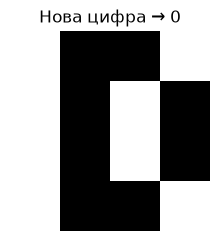

In [6]:
new_image = np.array([
    [0,1,1,0],
    [0,1,0,1],
    [0,1,0,1],
    [0,1,1,0],
],dtype=np.float64)
new_pred = int(mlp.predict(new_image.reshape(1,-1))[0])
probs = mlp.predict_proba(new_image.reshape(1,-1))[0]
print('Передбачений клас:',new_pred)
print('Імовірності класів:',dict(zip(mlp.classes_,np.round(probs,4))))
fig,ax=plt.subplots(figsize=(2.6,2.6))
ax.imshow(new_image,cmap='Greys',vmin=0,vmax=1)
ax.set_title(f'Нова цифра → {new_pred}')
ax.axis('off');fig.savefig(OUT/'05_new_digit_prediction.png',dpi=170,bbox_inches='tight');plt.show()

## ВИСНОВОК

Реалізовано класифікацію двох цифр за бінарними зображеннями 4×4. Базовий алгоритм KNN порівняно з MLP, гіперпараметри якого підібрано перехресною перевіркою на навчальній вибірці. Якість оцінено на окремих тестових зображеннях за Accuracy, F1 і матрицею помилок. Через невелику кількість початкових прикладів отримані значення метрик слід інтерпретувати обережно; вони характеризують саме це розбиття набору даних.